<a href="https://colab.research.google.com/github/xiaoemilyx/Spaceship-Titanic-ML/blob/main/Project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Using the Spaceship Titanic Dataset:**

The purpose of this project is to develop a supervised machine learning model that predicts whether a passenger aboard the Spaceship Titanic was transported to an alternate dimension.

Using passenger information such as age, home planet, destination, cryosleep status, and spending habits, I will investigate relationships between passenger characteristics and transportation outcomes.

This is a binary classification problem because the target final variable, Transported, has two possible outcomes: True or False.

Throughout this project, I will perform exploratory data analysis, prepare the dataset, train multiple  models, and evaluate their ability to generalize to unseen data.

Also, sorry, I don't know how to work Kaggle so I won't be uploading it onto there as a competition submission or a notebook... I don't know how to directly upload it as a notebook from Colab. :,)

Github Link:
Colab Link:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("train.csv")
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [3]:
#What is the structure of the dataset?
df.shape

(8693, 14)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


In [5]:
df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


Some Observations:


* Average age	= 28.83 years
* Median age	= 27 years
* Minimum age	= 0 years
* Maximum age	= 79 years
* Median spending	= 0 across all five spending categories
* Maximum FoodCourt spending	= 29,813
* Maximum Spa spending = 22,408

The maximum spending can suggest that the distrubtion is skewered to the left.

**How many passengers are in the dataset?**
This dataset contains 8,693 passengers and 14 columns.

**How many features are there?**
Those columns include 13 potential input features as well as one target variable. (Transported.)

**Which variables are numerical?**
Age, RoomService, FoodCourt, ShoppingMall, Spa, VRDeck.

**Which variables are categorical?**
HomePlanet, CyroSleep, Destination, VIP.

Something to note is that PassengerId, Cabin, and Name are stored as object, which means there is complication information in which we can't categorize it as numerical nor categorical.


**What is the target variable?**
The target variable is Transported, a boolean, which makes this dataset into a binary classification problem.

In [22]:
#Is the dataset balanced?
#Found that using value_counts would make sense
#from a quick tutorial online.
df['Transported'].value_counts()

,count
Transported,
True,4378
False,4315


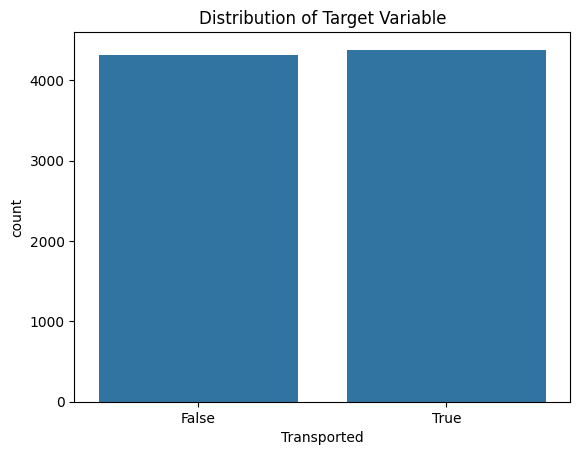

In [23]:
sns.countplot(data=df, x='Transported')
plt.title('Distribution of Target Variable')
plt.show()

This shows that the target variable is relatively balanced.

In [7]:
#Are there missing values?
df.isnull().sum()

,0
PassengerId,0
HomePlanet,201
CryoSleep,217
Cabin,199
Destination,182
Age,179
VIP,203
RoomService,181
FoodCourt,183
ShoppingMall,208


In [11]:
df.isnull().sum().sum()

np.int64(2324)

In [24]:
#How much is missing from each column?
df.isnull().sum() / len(df) * 100

,0
PassengerId,0.000000
HomePlanet,2.312205
CryoSleep,2.496261
Cabin,2.289198
Destination,2.093639
Age,2.059128
VIP,2.335212
RoomService,2.082135
FoodCourt,2.105142
ShoppingMall,2.392730


In [12]:
#What percentage are missing and we may drop?
df[df.isnull().any(axis=1)].shape[0] / len(df) * 100

24.007822385827676

Oh snap this is lowkey high...

At first, I thought missing data meant that the passenger was transported, but that is false. It just means that piece of infomration was not recorded.


Although approximately 24.01% of passengers have at least one missing value, each individual feature has less than 3% missing data. Removing all incomplete rows would result in a significant loss of training information.

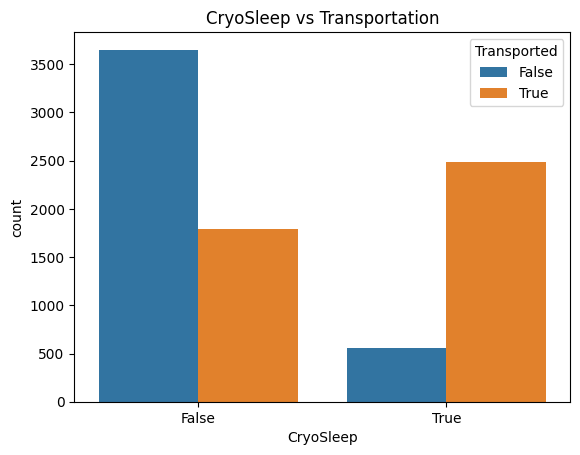

In [13]:
#Does cryosleep affect transportation?
sns.countplot(data=df, x='CryoSleep', hue='Transported')
plt.title('CryoSleep vs Transportation')
plt.show()

This graph shows that people in CyroSleep are more likely to be transported.

In [14]:
df.groupby('CryoSleep')['Transported'].mean()

,Transported
CryoSleep,
False,0.328921
True,0.817583


The results demonstrate a substantial relationship between CryoSleep status and transportation.

Approximately 81.76% of passengers in CryoSleep were transported, compared to only 32.89% of passengers who were not in CryoSleep. This suggests that CryoSleep may be an important  feature for predictions and should be saved during data preparation.


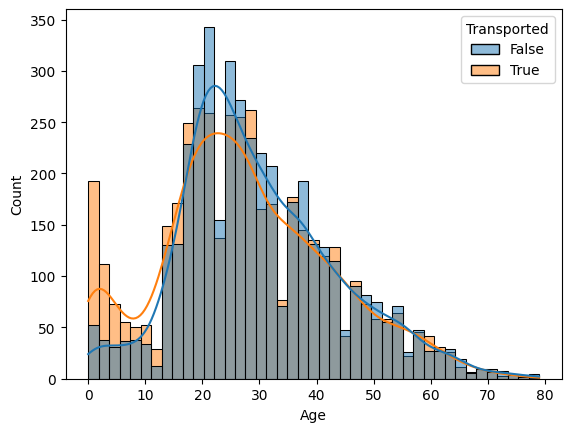

In [17]:
#Does age affect transportation?
sns.histplot(data=df, x='Age', hue='Transported', kde=True)
plt.show()

Using a KDE, it shows an easier line of best fit to observe the graph propely with the overlapping colors.
Because blue, or the false line shows to have a higher incline than the orange, true line, it shows that there were more non-transported adults from the range of 20-40 years old.

However, something to note is that people ages 0-20 years old were more likely to be successfully transported rather than not.

This graph also shows the age demographic of this spaceship.

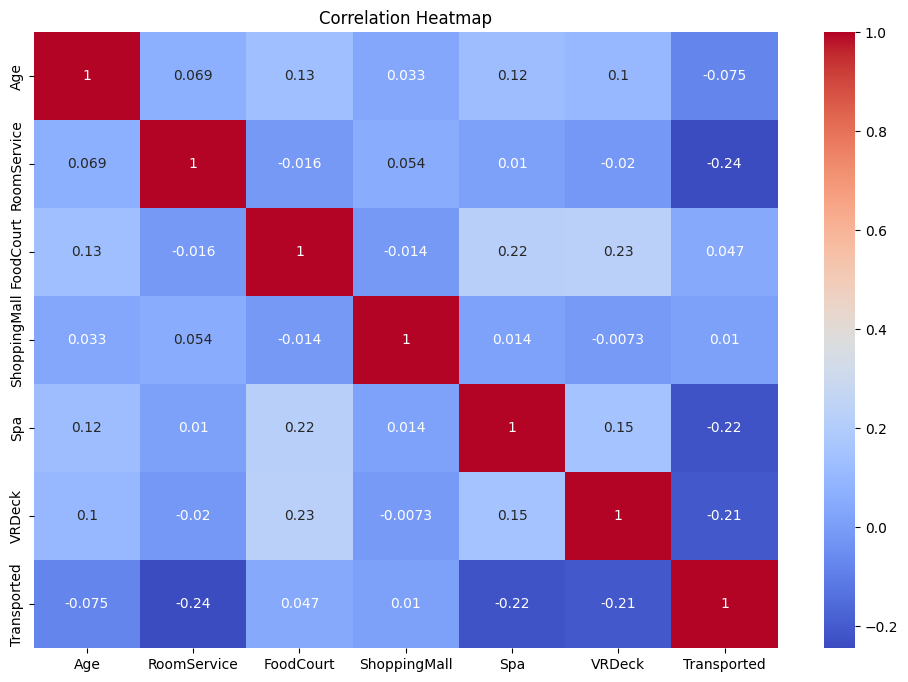

In [18]:
#Are spending habits related to transportation?
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Interpretations:


*   RoomService -> -0.24 -> Higher spending is associated with lower transportation rates.
*   Spa -> -0.22 -> A negative relationship.
* VRDeck -> -0.21 -> A negative relationship.
* Age -> -0.075 -> Very weak negative relationship.
* FoodCourt -> 0.047 -> Very weak positive relationship.
* ShoppingMall -> 0.01 -> Almost no linear relationship.



The correlation heatmap indicates that RoomService, Spa, and VRDeck have the strongest negative correlations with transportation among the numerical features.

This suggests that passengers who spent more on certain services were generally less likely to be transported.

However, none of the numerical variables demonstrate a strong  correlation with the target. Therefore, I will keep these features  because nonlinear relationships and interactions between variables may provide additional predictive information.

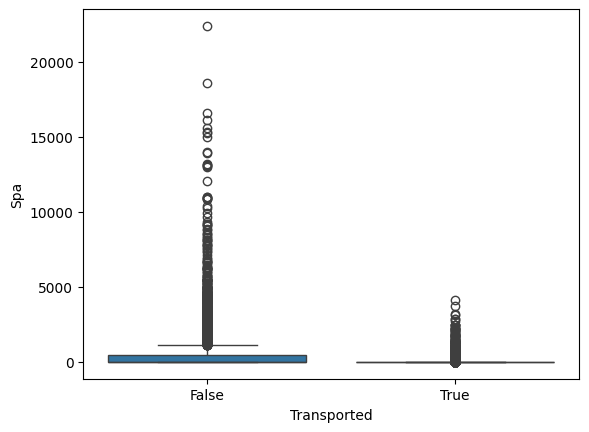

In [19]:
#Are there any outliers?
sns.boxplot(data=df, x='Transported', y='Spa')
plt.show()

OH MANY!

* Non-transported passengers have much higher extreme Spa spending values.

* The highest Spa spending among non-transported passengers exceeds 20,000.

* Transported passengers generally spend very little on Spa services.

* Both groups have numerous outliers.

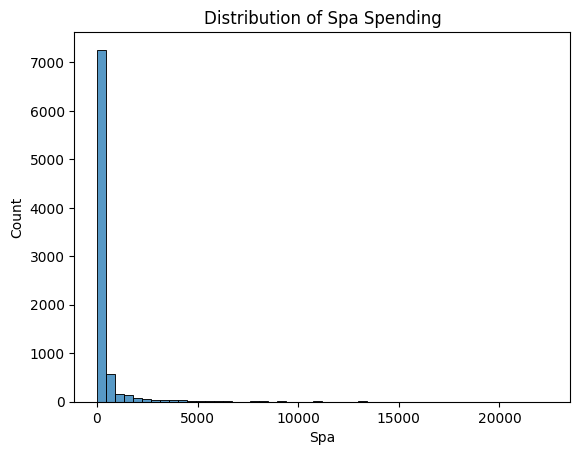

In [27]:
sns.histplot(data=df, x='Spa', bins=50)
plt.title('Distribution of Spa Spending')
plt.show()

The boxplot reveals numerous outliers in Spa spending, particularly among passengers who were not transported. The distribution is highly left-skewed, with many passengers spending little or nothing and a small proportion spending exceptionally large amounts.

Since these values may represent legitimate spending behavior rather than data entry errors, I will not remove them immediately.

Instead, I consider feature scaling or transformation during data preparation.

In [28]:
#Could CyroSleep Status be related to passenger spending?

df.groupby('CryoSleep')[
    ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].mean()

,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
CryoSleep,,,,,
False,350.146772,713.004316,270.586504,486.09294,475.716165
True,0.000000,0.000000,0.000000,0.00000,0.000000


In [30]:
df[df['CryoSleep'] == True][
    ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
].max()

,0
RoomService,0.0
FoodCourt,0.0
ShoppingMall,0.0
Spa,0.0
VRDeck,0.0


Yes, because sleeping passengers cannot purchase services.


The reason for this question was because:
* Passengers in CyroSleep are much more likely to be transported.
* Passengers who spend money on certain services are less likely to be transported.
* The median spending across every service is zero.

In [20]:
#Feature Engineering Ideas
#Used online resources to help figure out how to combine categories!
df['TotalSpending'] = df[
    ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].sum(axis=1, min_count=5)

In [38]:
X = df.drop('Transported', axis=1)
y = df['Transported']

In [39]:
#Split the dataset:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [35]:
df.select_dtypes(include='object').columns #identify remaining categorical variables

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'VIP',
       'Name'],
      dtype='object')

In [36]:
df = df.drop(columns=['Name', 'PassengerId', 'Cabin'], errors='ignore')

df = pd.get_dummies(df, dtype=int) #help I used outside research for this sorsoryr

In [43]:
df.isnull().sum()

,0
Age,179
RoomService,181
FoodCourt,183
ShoppingMall,208
Spa,183
VRDeck,188
Transported,0
TotalSpending,908
HomePlanet_Earth,0
HomePlanet_Europa,0


In [44]:
spending = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

df.loc[df['CryoSleep_True'] == 1, spending] = df.loc[
    df['CryoSleep_True'] == 1, spending
].fillna(0)

In [45]:
from sklearn.model_selection import train_test_split

X = df.drop('Transported', axis=1)
y = df['Transported']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [46]:
cols = ['Age'] + spending

X_train[cols] = X_train[cols].fillna(X_train[cols].median())
X_test[cols] = X_test[cols].fillna(X_train[cols].median())

In [47]:
X_train['TotalSpending'] = X_train[spending].sum(axis=1)
X_test['TotalSpending'] = X_test[spending].sum(axis=1)

I got outside help for this but I'll explain it:

During my exploratory data analysis, I discovered that passengers in CryoSleep had no recorded spending across the five available services.

Therefore, I filled their missing spending values with zero rather than using a general imputation method.

For the remaining missing numerical values, I used median imputation because the spending distributions contained numerous outliers.

Finally, I recalculated TotalSpending to ensure that the  feature accurately reflected the cleaned spending values.

In [48]:
X_train.isnull().sum()
X_test.isnull().sum()

,0
Age,0
RoomService,0
FoodCourt,0
ShoppingMall,0
Spa,0
VRDeck,0
TotalSpending,0
HomePlanet_Earth,0
HomePlanet_Europa,0
HomePlanet_Mars,0


In [49]:
#How accurately can a simple classification model predict whether a passenger was transported?
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

In [50]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

Random Forest combines multiple decision trees to make predictions. Unlike Logistic Regression, Random Forest can capture nonlinear relationships and complex interactions between features. Combining multiple trees also helps reduce variance.

What Each Metric Tells Me:
* Accuracy = How many passengers were correctly classified.
* Precision = Of those predicted to be transported, how many actually were.
* Recall = Of those actually transported, how many did we identify?
* F1-score = How well does the model balance precision and recal.

In [51]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1-score:", f1_score(y_test, y_pred_lr))

Accuracy: 0.7734330074755607
Precision: 0.7607758620689655
Recall: 0.8041002277904328
F1-score: 0.7818383167220376


In [52]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-score:", f1_score(y_test, y_pred_rf))

Accuracy: 0.7745830937320299
Precision: 0.7748868778280543
Recall: 0.7801822323462415
F1-score: 0.7775255391600454


I initially expected Random Forest to perform better because it can capture more complex and nonlinear relationships between features.

 However, both models achieved around 77% accuracy.

 Random Forest had slightly higher accuracy and precision, while Logistic Regression had higher recall and F1-score.

 This suggests that increasing model complexity does not result in significantly better performance.

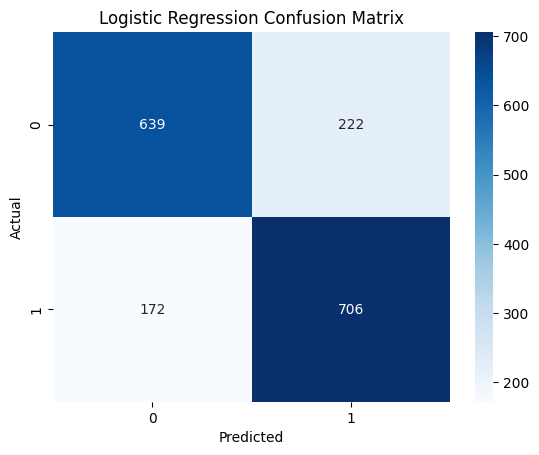

In [53]:
#What types of mistakes are my models making?
from sklearn.metrics import confusion_matrix

sns.heatmap(confusion_matrix(y_test, y_pred_lr),
            annot=True, fmt='d', cmap='Blues')

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

The Logistic Regression model correctly classified 1,345 out of 1,739 passengers.

However, it produced 222 false positives and 172 false negatives. Since there are more false positives than false negatives, the model tends to overpredict whether passengers were transported.

In [54]:
#Is the RandomForest overrfitting?
print("Training Accuracy:", rf.score(X_train, y_train))
print("Testing Accuracy:", rf.score(X_test, y_test))

Training Accuracy: 0.9381650848432557
Testing Accuracy: 0.7745830937320299


Yes, this shows evidence of some overfitting.

In [55]:
#Did creating TotalSpending improve my model?

rf2 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf2.fit(X_train.drop(columns=['TotalSpending']), y_train)

y_pred_rf2 = rf2.predict(
    X_test.drop(columns=['TotalSpending'])
)

print("Accuracy:", accuracy_score(y_test, y_pred_rf2))

Accuracy: 0.7797584818861415


It improved by about 0.52+ percentage points.

One possible explanation is feature redundancy, since TotalSpending is calculated using five existing features. The model may already be capable of identifying relationships between individual spending categories and transportation status.

However, the improvement is relatively small, so further testing through cross-validation would be necessary to determine whether removing this feature consistently improves performance.

In [56]:
print("Training Accuracy:", rf.score(X_train, y_train))
print("Testing Accuracy:", rf.score(X_test, y_test))

Training Accuracy: 0.9381650848432557
Testing Accuracy: 0.7745830937320299


Yes, this is shwoing signs of overfitting.


 The large difference of 16.36 percentage points suggests that the model is overfitting the training data.

 Although Random Forest is designed to reduce variance by combining multiple decision trees, individual trees may still become overly complex.


**Which model performed the best, and what did I learn?**

Throughout this project, I investigated which passenger characteristics could help predict whether a passenger was transported. During exploratory data analysis, I discovered that passengers in CryoSleep were significantly more likely to be transported and that certain spending categories were negatively correlated with transportation.

I trained and evaluated Logistic Regression and Random Forest models. Both achieved approximately 77% accuracy, with Random Forest achieving slightly higher accuracy and Logistic Regression achieving higher recall and F1-score.

I also investigated whether creating a TotalSpending feature improved performance. Surprisingly, removing this feature increased Random Forest's accuracy from 77.46% to 77.98%, possibly due to feature redundancy. (An initial guess of mine...)

Additionally, the original Random Forest achieved 93.82% training accuracy but only 77.46% testing accuracy, suggesting overfitting.

Overall, Random Forest without TotalSpending achieved the highest observed testing accuracy.

This project demonstrated that increasing model complexity and adding more features do not necessarily improve predictive performance. In the future, I could investigate cross-validation to improve my findings.